# Unit 2 — Assignment 2: Matrix Algebra & Systems of Equations

**Team members:** Raghad Alasmari, Rawan Alsubaie, Norah Alsuwailem, Fahad Al-Nahi

## Objectives
- Represent real-world data using matrices.
- Perform matrix operations **manually** and using NumPy.
- Apply matrix multiplication in AI.
- Understand determinant, inverse, identity matrix, transpose, and rank.
- Solve systems of equations using NumPy.
- Connect Linear Algebra with Machine Learning.

**Dataset used in Missions 1, 2, and 3:**

| House | Area | Bedrooms | Age |
|---|---|---|---|
| H1 | 120 | 3 | 10 |
| H2 | 150 | 4 | 8 |
| H3 | 180 | 4 | 6 |
| H4 | 210 | 5 | 4 |


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
feature_names = ["Area", "Bedrooms", "Age"]
house_names = ["H1", "H2", "H3", "H4"]
print("Libraries loaded.")

Libraries loaded.


---
# Mission 1 — Understanding the Matrix

## Manual representation

Writing each house as a row and each feature as a column gives the data matrix

$$
X=\begin{bmatrix}
120&3&10\\
150&4&8\\
180&4&6\\
210&5&4
\end{bmatrix}
\qquad
\begin{matrix}\leftarrow H1\\\leftarrow H2\\\leftarrow H3\\\leftarrow H4\end{matrix}
$$

with columns in the order **Area, Bedrooms, Age**.

## Shape

- **Number of rows:** $4$ (one per house)
- **Number of columns:** $3$ (one per feature)
- **Shape:** $4\times3$, written in NumPy as `(4, 3)`.

## What do rows and columns represent?

- **Each row** is one **house (sample / observation)**. Row 1, $[120,\ 3,\ 10]$, is house H1: 120 m², 3 bedrooms, 10 years old.
- **Each column** is one **feature (variable)** measured for every house. Column 1, $[120,150,180,210]^T$, holds the Area of all four houses.

In [4]:
X = np.array([
    [120, 3, 10],   # H1
    [150, 4,  8],   # H2
    [180, 4,  6],   # H3
    [210, 5,  4],   # H4
], dtype=float)

print("Data matrix X:\n", X)
print("Shape:", X.shape)
print("Number of rows (houses):", X.shape[0])
print("Number of columns (features):", X.shape[1])
print("Row 0 -> house H1:", X[0])
print("Column 0 -> Area of all houses:", X[:, 0])

Data matrix X:
 [[120.   3.  10.]
 [150.   4.   8.]
 [180.   4.   6.]
 [210.   5.   4.]]
Shape: (4, 3)
Number of rows (houses): 4
Number of columns (features): 3
Row 0 -> house H1: [120.   3.  10.]
Column 0 -> Area of all houses: [120. 150. 180. 210.]


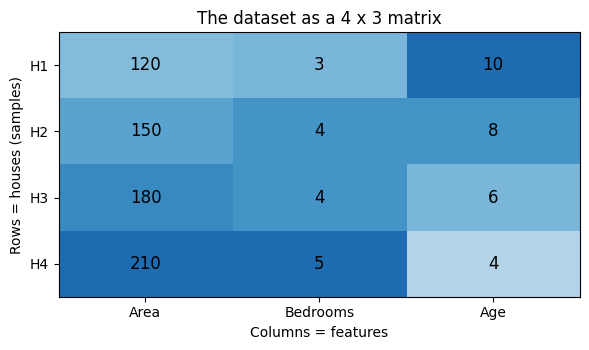

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow(X / X.max(axis=0), cmap="Blues", vmin=0, vmax=1.3, aspect="auto")
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        ax.text(j, i, f"{X[i, j]:g}", ha="center", va="center", fontsize=12)
ax.set_xticks(range(3)); ax.set_xticklabels(feature_names)
ax.set_yticks(range(4)); ax.set_yticklabels(house_names)
ax.set_xlabel("Columns = features"); ax.set_ylabel("Rows = houses (samples)")
ax.set_title("The dataset as a 4 x 3 matrix")
plt.tight_layout()
plt.show()

### AI Insight — What do rows and columns represent in Machine Learning?

In Machine Learning the dataset is stored as a **feature matrix** $X$ of shape $(n\_samples,\ n\_features)$. **Rows** are **samples** (observations, records): each row is one example the model learns from or predicts for. **Columns** are **features** (input variables) that describe every sample. A target column such as *Price* would be stored separately as the label vector $y$. Libraries such as scikit-learn expect exactly this layout, so a model processes one row at a time and learns one weight per column.

---
# Mission 2 — Matrix Operations

Each operation below is applied to the **original** matrix $X$, so the effect of every operation can be seen on its own.

## 1. Add 2 to every Age value (column 3)

$$
\text{Age}+2=\begin{bmatrix}10+2\\8+2\\6+2\\4+2\end{bmatrix}=\begin{bmatrix}12\\10\\8\\6\end{bmatrix}
$$

## 2. Subtract 1 from every Age value

$$
\text{Age}-1=\begin{bmatrix}10-1\\8-1\\6-1\\4-1\end{bmatrix}=\begin{bmatrix}9\\7\\5\\3\end{bmatrix}
$$

*(If the two operations were applied one after the other, the net change would be $+2-1=+1$, giving $[11,\ 9,\ 7,\ 5]^T$.)*

## 3. Multiply the Area column by 1.1 (scalar multiplication)

$$
1.1\times\begin{bmatrix}120\\150\\180\\210\end{bmatrix}
=\begin{bmatrix}132\\165\\198\\231\end{bmatrix}
$$

This is a 10% increase in every Area value.

## 4. Transpose

The transpose swaps rows and columns: entry $(i,j)$ of $X$ becomes entry $(j,i)$ of $X^T$.

$$
X^T=\begin{bmatrix}
120&150&180&210\\
3&4&4&5\\
10&8&6&4
\end{bmatrix}
\qquad (3\times4)
$$

Now each **row** is a feature and each **column** is a house.

In [9]:
# 1. Add 2 to Age (work on a copy so X is unchanged)
X_age_plus2 = X.copy()
X_age_plus2[:, 2] = X_age_plus2[:, 2] + 2

# 2. Subtract 1 from Age
X_age_minus1 = X.copy()
X_age_minus1[:, 2] = X_age_minus1[:, 2] - 1

# 3. Multiply Area by 1.1
X_area_scaled = X.copy()
X_area_scaled[:, 0] = X_area_scaled[:, 0] * 1.1

# 4. Transpose
X_T = X.T

print("Age + 2:\n", X_age_plus2)
print("\nAge - 1:\n", X_age_minus1)
print("\nArea x 1.1:\n", X_area_scaled)
print("\nTranspose X.T:\n", X_T)
print("\nShape before transpose:", X.shape, "| after:", X_T.shape)

Age + 2:
 [[120.   3.  12.]
 [150.   4.  10.]
 [180.   4.   8.]
 [210.   5.   6.]]

Age - 1:
 [[120.   3.   9.]
 [150.   4.   7.]
 [180.   4.   5.]
 [210.   5.   3.]]

Area x 1.1:
 [[132.   3.  10.]
 [165.   4.   8.]
 [198.   4.   6.]
 [231.   5.   4.]]

Transpose X.T:
 [[120. 150. 180. 210.]
 [  3.   4.   4.   5.]
 [ 10.   8.   6.   4.]]

Shape before transpose: (4, 3) | after: (3, 4)


### AI Insight

**Which operation changes values?** Addition, subtraction, and scalar multiplication. They change the **numbers** inside the matrix (Age shifts by $+2$ or $-1$, Area grows by 10%), but the shape stays $4\times3$. In ML these are the same kind of operations used in **feature scaling and preprocessing** (for example, centering by subtracting the mean, or standardizing).

**Which operation changes structure?** The **transpose**. It keeps every value but rearranges them, turning a $4\times3$ matrix into a $3\times4$ matrix.

**Why is transpose useful?**
- It makes matrix shapes **compatible** for multiplication (inner dimensions must match).
- It appears in core ML formulas: the covariance matrix $\frac{1}{n-1}X^TX$ and the Normal Equation $w=(X^TX)^{-1}X^Ty$ for linear regression.
- It lets us switch between a "one row per sample" view and a "one row per feature" view of the same data.

---
# Mission 3 — AI Prediction

## Weight matrix

| Feature | Weight |
|---|---|
| Area | 2 |
| Bedrooms | 20 |
| Age | −5 |

$$
w=\begin{bmatrix}2\\20\\-5\end{bmatrix}\qquad(3\times1)
$$

The negative weight on Age means older houses get a **lower** score.

## Matrix multiplication

The shapes are compatible because the inner dimensions match: $(4\times\mathbf{3})\cdot(\mathbf{3}\times1)\rightarrow(4\times1)$.

$$
\hat y = Xw=
\begin{bmatrix}120&3&10\\150&4&8\\180&4&6\\210&5&4\end{bmatrix}
\begin{bmatrix}2\\20\\-5\end{bmatrix}
$$

Each prediction is the dot product of one row with $w$:

$$
\begin{aligned}
H1&: 120(2)+3(20)+10(-5)=240+60-50=\mathbf{250}\\
H2&: 150(2)+4(20)+8(-5)=300+80-40=\mathbf{340}\\
H3&: 180(2)+4(20)+6(-5)=360+80-30=\mathbf{410}\\
H4&: 210(2)+5(20)+4(-5)=420+100-20=\mathbf{500}
\end{aligned}
$$

$$
\boxed{\hat y=\begin{bmatrix}250\\340\\410\\500\end{bmatrix}}
$$

H4 (largest, most bedrooms, newest) gets the highest score; H1 gets the lowest.

In [13]:
w = np.array([[2], [20], [-5]], dtype=float)   # 3 x 1 weight matrix
print("Weight matrix w:\n", w, "\nShape:", w.shape)

y_hat = X @ w                                    # (4 x 3) @ (3 x 1) -> (4 x 1)
print("\nPrediction scores X @ w:\n", y_hat, "\nShape:", y_hat.shape)

for name, row, score in zip(house_names, X, y_hat.ravel()):
    terms = " + ".join(f"{x:g}*({wi:g})" for x, wi in zip(row, w.ravel()))
    print(f"{name}: {terms} = {score:g}")

Weight matrix w:
 [[ 2.]
 [20.]
 [-5.]] 
Shape: (3, 1)

Prediction scores X @ w:
 [[250.]
 [340.]
 [410.]
 [500.]] 
Shape: (4, 1)
H1: 120*(2) + 3*(20) + 10*(-5) = 250
H2: 150*(2) + 4*(20) + 8*(-5) = 340
H3: 180*(2) + 4*(20) + 6*(-5) = 410
H4: 210*(2) + 5*(20) + 4*(-5) = 500


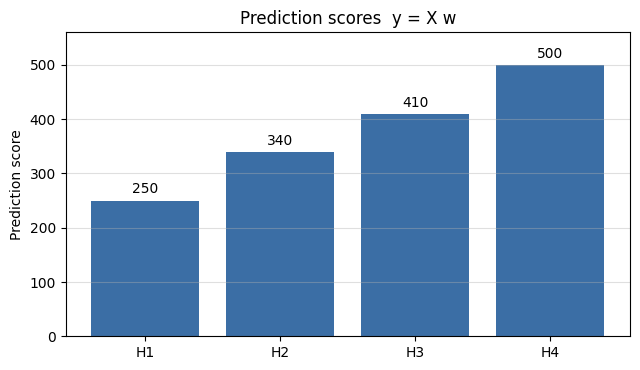

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.bar(house_names, y_hat.ravel(), color="#3b6ea5")
ax.bar_label(bars, fmt="%g", padding=3)
ax.set_ylabel("Prediction score")
ax.set_title("Prediction scores  y = X w")
ax.set_ylim(0, 560)
ax.grid(True, axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

### AI Insight — Where is matrix multiplication used in AI?

Matrix multiplication is the core computation of almost every model:
- **Linear and logistic regression:** predictions for all samples at once are $\hat y = Xw + b$, exactly what we computed above.
- **Neural networks:** every dense layer computes $h=\sigma(XW+b)$; deep learning is mostly long chains of matrix multiplications, which is why GPUs (built for fast matrix math) are used.
- **Transformers / LLMs:** attention uses $QK^T$ and multiplies by $V$; embeddings are looked up and projected with matrices.
- **Recommendation systems and PCA:** user–item factorization and projecting data onto principal components are matrix products.

Doing it as one matrix operation instead of a loop over rows is far faster and is called **vectorization**.

---
# Mission 4 — Detecting Redundant Features

The company added a new feature, **Rooms**, where $\text{Rooms}=2\times\text{Bedrooms}$.

$$
X_{new}=\begin{bmatrix}
120&3&10&6\\
150&4&8&8\\
180&4&6&8\\
210&5&4&10
\end{bmatrix}\qquad(4\times4)
$$

## Manual rank calculation

**Rank** = the number of linearly independent columns (equivalently, rows).

**Step 1 — find the dependency.** Column 4 is exactly $2\times$ column 2:

$$
\begin{bmatrix}6\\8\\8\\10\end{bmatrix}=2\begin{bmatrix}3\\4\\4\\5\end{bmatrix}
\quad\Longrightarrow\quad
\text{col}_4-2\,\text{col}_2=\mathbf 0 .
$$

So column 4 adds no new information, and the rank is **at most 3**. It also means $\det(X_{new})=0$.

**Step 2 — check the remaining three columns.** If Area, Bedrooms, and Age are independent, some $3\times3$ sub-matrix has a nonzero determinant. Take rows H1–H3:

$$
\begin{aligned}
\det\begin{bmatrix}120&3&10\\150&4&8\\180&4&6\end{bmatrix}
&=120(4\cdot6-8\cdot4)-3(150\cdot6-8\cdot180)+10(150\cdot4-4\cdot180)\\
&=120(-8)-3(-540)+10(-120)\\
&=-960+1620-1200=-540\neq0 .
\end{aligned}
$$

The three original features are independent, therefore

$$\boxed{\operatorname{rank}(X_{new})=3}$$

even though the matrix has 4 columns. **One column is redundant.**

In [14]:
rooms = 2 * X[:, 1]
X_new = np.column_stack([X, rooms])
print("New matrix X_new (Area, Bedrooms, Age, Rooms):\n", X_new)
print("Shape:", X_new.shape)

rank_original = np.linalg.matrix_rank(X)
rank_new = np.linalg.matrix_rank(X_new)
print("\nRank of original X (3 features):", rank_original)
print("Rank of X_new (4 features):     ", rank_new)
print("Number of columns in X_new:     ", X_new.shape[1])

minor = np.linalg.det(X_new[:3, :3])
print(f"\ndet of 3x3 minor (rows H1-H3, first 3 columns) = {minor:.4f}")
print(f"det(X_new) = {np.linalg.det(X_new):.4f}")
print("Rooms == 2 * Bedrooms for every house:", np.allclose(X_new[:, 3], 2 * X_new[:, 1]))

print("\nRank verified: 4 columns but only 3 independent -> 1 redundant feature.")

New matrix X_new (Area, Bedrooms, Age, Rooms):
 [[120.   3.  10.   6.]
 [150.   4.   8.   8.]
 [180.   4.   6.   8.]
 [210.   5.   4.  10.]]
Shape: (4, 4)

Rank of original X (3 features): 3
Rank of X_new (4 features):      3
Number of columns in X_new:      4

det of 3x3 minor (rows H1-H3, first 3 columns) = -540.0000
det(X_new) = 0.0000
Rooms == 2 * Bedrooms for every house: True

Rank verified: 4 columns but only 3 independent -> 1 redundant feature.


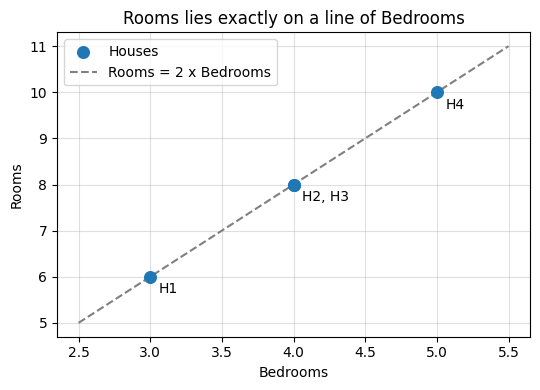

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(X_new[:, 1], X_new[:, 3], s=70, zorder=3, label="Houses")
b = np.linspace(2.5, 5.5, 10)
ax.plot(b, 2 * b, "--", color="gray", label="Rooms = 2 x Bedrooms")
labels = {}
for name, x, y in zip(house_names, X_new[:, 1], X_new[:, 3]):
    labels.setdefault((x, y), []).append(name)   # H2 and H3 share the same point
for (x, y), names in labels.items():
    ax.annotate(", ".join(names), (x, y), textcoords="offset points", xytext=(6, -12))
ax.set_xlabel("Bedrooms"); ax.set_ylabel("Rooms")
ax.set_title("Rooms lies exactly on a line of Bedrooms")
ax.grid(True, alpha=0.4); ax.legend()
plt.tight_layout()
plt.show()

### Findings

- $X_{new}$ has **4 columns but rank 3**: the Rooms column is a linear combination ($2\times$) of Bedrooms.
- Rooms carries **no new information**; every value can be predicted perfectly from Bedrooms.
- Because the columns are dependent, $\det(X_{new})=0$, so the matrix is **singular** (not invertible).
- The fix is simple: **drop Rooms** (or Bedrooms) and keep 3 features.

### AI Insight — Why are redundant features harmful?

- **Multicollinearity:** when features are perfectly correlated, $X^TX$ becomes singular, so linear regression cannot find a unique set of weights. Weights become unstable and hard to interpret (the model cannot tell whether the effect comes from Bedrooms or Rooms).
- **Wasted computation and memory**, with no gain in information.
- **Higher risk of overfitting** and the "curse of dimensionality" as the number of features grows without adding real signal.
- Checking the **rank** (or correlation, or PCA eigenvalues close to zero) is a quick way to detect redundant features before training.

---
# Mission 5 — Determinant, Identity Matrix & Inverse

$$
A=\begin{bmatrix}2&1\\4&2\end{bmatrix},\qquad
B=\begin{bmatrix}2&1\\3&2\end{bmatrix},\qquad
I=\begin{bmatrix}1&0\\0&1\end{bmatrix}
$$

## Determinants (manual)

For a $2\times2$ matrix, $\det\begin{bmatrix}a&b\\c&d\end{bmatrix}=ad-bc$.

$$
\det(A)=(2)(2)-(1)(4)=4-4=\boxed{0}
$$

$$
\det(B)=(2)(2)-(1)(3)=4-3=\boxed{1}
$$

## Identity matrix

$$
A\,I=\begin{bmatrix}2(1)+1(0)&2(0)+1(1)\\4(1)+2(0)&4(0)+2(1)\end{bmatrix}=\begin{bmatrix}2&1\\4&2\end{bmatrix}=A
$$

$$
B\,I=\begin{bmatrix}2(1)+1(0)&2(0)+1(1)\\3(1)+2(0)&3(0)+2(1)\end{bmatrix}=\begin{bmatrix}2&1\\3&2\end{bmatrix}=B
$$

The identity matrix acts like the number $1$ in multiplication: it leaves any matrix unchanged.

## Which matrix is invertible?

A square matrix is invertible **only if its determinant is not zero**.
- $\det(A)=0$ → $A$ is **singular**, **not invertible**.
- $\det(B)=1\neq0$ → $B$ is **invertible**.

## Inverse of B (manual)

$$
B^{-1}=\frac{1}{\det(B)}\begin{bmatrix}d&-b\\-c&a\end{bmatrix}
=\frac{1}{1}\begin{bmatrix}2&-1\\-3&2\end{bmatrix}
=\begin{bmatrix}2&-1\\-3&2\end{bmatrix}
$$

Check: $BB^{-1}=\begin{bmatrix}2(2)+1(-3)&2(-1)+1(2)\\3(2)+2(-3)&3(-1)+2(2)\end{bmatrix}=\begin{bmatrix}1&0\\0&1\end{bmatrix}=I$ ✓

## Why A has no inverse

The second row of $A$ is exactly **2 × the first row** ($[4,2]=2[2,1]$). The two rows point in the same direction, so $A$ squashes the whole 2D plane onto a single line. Information is lost (many different inputs give the same output), so there is no way to "undo" the transformation. In the formula, $A^{-1}=\frac{1}{\det(A)}(\dots)$ would require dividing by $0$, which is undefined.

In [16]:
A = np.array([[2, 1], [4, 2]], dtype=float)
B = np.array([[2, 1], [3, 2]], dtype=float)
I = np.eye(2)

det_A = np.linalg.det(A)
det_B = np.linalg.det(B)
print(f"det(A) = {det_A:.4f}")
print(f"det(B) = {det_B:.4f}")

print("\nA @ I =\n", A @ I, "\nEquals A:", np.allclose(A @ I, A))
print("\nB @ I =\n", B @ I, "\nEquals B:", np.allclose(B @ I, B))

for name, M, d in [("A", A, det_A), ("B", B, det_B)]:
    print(f"\n{name} invertible? {not np.isclose(d, 0)}  (rank = {np.linalg.matrix_rank(M)})")

det(A) = 0.0000
det(B) = 1.0000

A @ I =
 [[2. 1.]
 [4. 2.]] 
Equals A: True

B @ I =
 [[2. 1.]
 [3. 2.]] 
Equals B: True

A invertible? False  (rank = 1)

B invertible? True  (rank = 2)


In [17]:
B_inv = np.linalg.inv(B)
print("Inverse of B (NumPy):\n", B_inv)
print("\nB @ B_inv =\n", np.round(B @ B_inv, 10) + 0.0)
print("B_inv @ B =\n", np.round(B_inv @ B, 10) + 0.0)
print("Manual inverse matches NumPy, and B @ B_inv = I.")

# Trying to invert A raises an error, because A is singular
try:
    np.linalg.inv(A)
except np.linalg.LinAlgError as err:
    print("\nnp.linalg.inv(A) failed ->", err)

Inverse of B (NumPy):
 [[ 2. -1.]
 [-3.  2.]]

B @ B_inv =
 [[1. 0.]
 [0. 1.]]
B_inv @ B =
 [[1. 0.]
 [0. 1.]]
Manual inverse matches NumPy, and B @ B_inv = I.

np.linalg.inv(A) failed -> Singular matrix


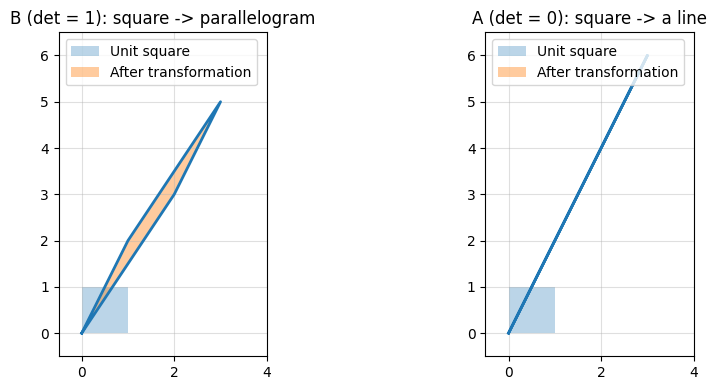

In [18]:
square = np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]], dtype=float)  # unit square corners
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, M, title in [(axes[0], B, "B (det = 1): square -> parallelogram"),
                     (axes[1], A, "A (det = 0): square -> a line")]:
    out = M @ square
    ax.fill(square[0], square[1], alpha=0.3, label="Unit square")
    ax.fill(out[0], out[1], alpha=0.4, label="After transformation")
    ax.plot(out[0], out[1], lw=2)
    ax.set_xlim(-0.5, 4); ax.set_ylim(-0.5, 6.5); ax.set_aspect("equal")
    ax.grid(True, alpha=0.4); ax.set_title(title); ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### AI Insight

**What does determinant = 0 mean?** The determinant measures how a matrix scales **area** (or volume). $\det=0$ means the transformation collapses the space into a lower dimension (a plane onto a line, as $A$ does in the plot). Equivalently, the rows/columns are linearly dependent and the rank is less than full. The matrix is called **singular**.

**Why can't a singular matrix be inverted?** An inverse must undo the transformation, but a singular matrix maps many different inputs to the same output, so the original input cannot be recovered. Algebraically, $A^{-1}=\frac{1}{\det A}\operatorname{adj}(A)$ would require division by zero.

**Why is the inverse important in Machine Learning?**
- **Linear regression (Normal Equation):** $w=(X^TX)^{-1}X^Ty$ gives the best weights in one step, but only if $X^TX$ is invertible. Redundant features (Mission 4) make it singular, which is why techniques such as Ridge regularization ($X^TX+\lambda I$) or the pseudo-inverse are used.
- **Solving systems** $Ax=b$ as $x=A^{-1}b$ (Mission 6).
- **Statistics and probabilistic models:** the inverse covariance matrix appears in the multivariate Gaussian, Mahalanobis distance, and Gaussian Processes.

---
# Mission 6 — Solving Linear Systems

$$
\begin{cases}
2x+y=7\\
x-y=2
\end{cases}
$$

## Matrix representation $A\mathbf{x}=\mathbf{b}$

$$
\underbrace{\begin{bmatrix}2&1\\1&-1\end{bmatrix}}_{A}
\underbrace{\begin{bmatrix}x\\y\end{bmatrix}}_{\mathbf x}
=\underbrace{\begin{bmatrix}7\\2\end{bmatrix}}_{\mathbf b}
$$

## Manual solution 1 — elimination

Add the two equations to eliminate $y$:

$$
(2x+y)+(x-y)=7+2\ \Rightarrow\ 3x=9\ \Rightarrow\ \boxed{x=3}
$$

Substitute into $x-y=2$: $\ 3-y=2\ \Rightarrow\ \boxed{y=1}$

## Manual solution 2 — inverse matrix

$$
\det(A)=(2)(-1)-(1)(1)=-3\neq0\quad\Rightarrow\quad A \text{ is invertible}
$$

$$
A^{-1}=\frac{1}{-3}\begin{bmatrix}-1&-1\\-1&2\end{bmatrix}
=\begin{bmatrix}\tfrac13&\tfrac13\\[2pt]\tfrac13&-\tfrac23\end{bmatrix}
$$

$$
\mathbf x=A^{-1}\mathbf b=
\begin{bmatrix}\tfrac13(7)+\tfrac13(2)\\[2pt]\tfrac13(7)-\tfrac23(2)\end{bmatrix}
=\begin{bmatrix}3\\1\end{bmatrix}
$$

**Check:** $2(3)+1=7$ ✓ and $3-1=2$ ✓

In [19]:
A_sys = np.array([[2, 1], [1, -1]], dtype=float)
b_sys = np.array([7, 2], dtype=float)

solution = np.linalg.solve(A_sys, b_sys) # recommended method
solution_inv = np.linalg.inv(A_sys) @ b_sys # inverse method, for comparison
manual = np.array([3, 1], dtype=float)

print(f"det(A) = {np.linalg.det(A_sys):.4f}")
print("A inverse:\n", np.linalg.inv(A_sys))
print("\nnp.linalg.solve  ->  x = %g, y = %g" % tuple(solution))
print("inv(A) @ b       ->  x = %g, y = %g" % tuple(solution_inv))
print("Manual solution  ->  x = %g, y = %g" % tuple(manual))
print("\nA @ solution =", A_sys @ solution, "| b =", b_sys)

print("Manual and NumPy solutions match.")

det(A) = -3.0000
A inverse:
 [[ 0.3333  0.3333]
 [ 0.3333 -0.6667]]

np.linalg.solve  ->  x = 3, y = 1
inv(A) @ b       ->  x = 3, y = 1
Manual solution  ->  x = 3, y = 1

A @ solution = [7. 2.] | b = [7. 2.]
Manual and NumPy solutions match.


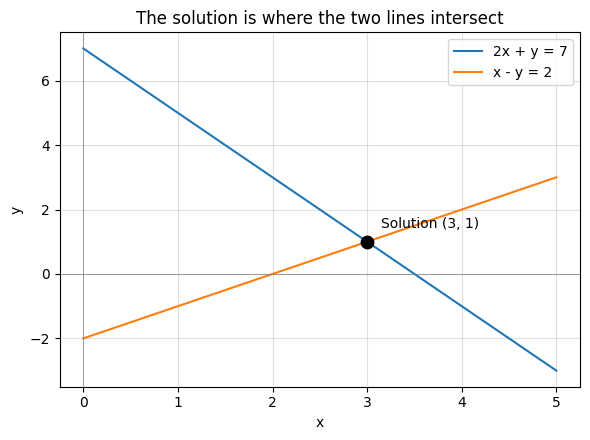

In [20]:
xs = np.linspace(0, 5, 100)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(xs, 7 - 2 * xs, label="2x + y = 7")
ax.plot(xs, xs - 2, label="x - y = 2")
ax.scatter(*solution, s=80, color="black", zorder=3)
ax.annotate("Solution (3, 1)", solution, textcoords="offset points", xytext=(10, 10))
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("The solution is where the two lines intersect")
ax.grid(True, alpha=0.4); ax.legend()
plt.tight_layout()
plt.show()

## Comparison of both solutions

| Method | x | y |
|---|---|---|
| Manual (elimination) | 3 | 1 |
| Manual (inverse matrix) | 3 | 1 |
| NumPy `np.linalg.solve` | 3 | 1 |
| NumPy `np.linalg.inv(A) @ b` | 3 | 1 |

All four methods agree. Geometrically, the solution $(3,1)$ is the single point where the two lines cross. In practice `np.linalg.solve` is preferred over computing the inverse, because it is faster and more numerically stable.

### AI Insight — Why are systems of equations important in Machine Learning?

- **Training linear regression** means solving a system: the Normal Equation $(X^TX)\,w=X^Ty$ is a linear system whose unknowns are the model weights.
- Many algorithms reduce to solving $A\mathbf x=\mathbf b$ internally: least squares, Gaussian Processes, Newton's method in optimization, and Kalman filters.
- Real datasets usually have **more equations (samples) than unknowns (weights)**, so the system has no exact solution. ML then finds the **best approximate** solution that minimizes error (least squares, `np.linalg.lstsq`).
- Whether a system has one, none, or infinitely many solutions connects back to **rank and determinant** (Missions 4 and 5): redundant features give infinitely many equally good weight vectors.

---
# Final Summary

| Mission | Main result |
|---|---|
| 1 — Understanding the Matrix | $X$ is $4\times3$: rows = houses (samples), columns = features |
| 2 — Matrix Operations | Age+2 → $[12,10,8,6]$; Age−1 → $[9,7,5,3]$; Area×1.1 → $[132,165,198,231]$; $X^T$ is $3\times4$ |
| 3 — AI Prediction | $Xw=[250,\ 340,\ 410,\ 500]^T$ |
| 4 — Redundant Features | 4 columns, **rank 3** → Rooms is redundant |
| 5 — Determinant & Inverse | $\det A=0$ (singular), $\det B=1$, $B^{-1}=\begin{bmatrix}2&-1\\-3&2\end{bmatrix}$ |
| 6 — Linear Systems | $x=3,\ y=1$ (manual = NumPy) |

